# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.trees import xfastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H' # '15min'
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 10

In [5]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_1h_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
                'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                'powerfactor3_lag_1h', 'powerfactor3_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(554, 43), y=(554,)
First valid split shape: X=(573, 43), y=(573,)

Memory usage:
Train: 5.35 MB
Valid: 1.24 MB
Test: 0.36 MB
Total: 6.95 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00

Time: 0.01 seconds
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-05 13:00:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Model's memory usage: 0.024162 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2631
	MAE: 0.1573
	MAPE: 19.9237%

Directional Metrics:
	Directional Accuracy: 43.3566%
	First-Diff Correlation: -0.1062

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spi

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-29 10:00:00

Time: 0.01 seconds
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2285
	MAE: 0.1480
	MAPE: 26.8072%

Directional Metrics:
	Directional Accuracy: 42.2339%
	First-Diff Correlation: 0.2325

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-26 09:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2087
	MAE: 0.1312
	MAPE: 30.4092%

Directional Metrics:
	Directional Accuracy: 41.0122%
	First-Diff Correlation: 0.1794

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3571
		Recall: 0.2941
		F1: 0.3226
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2046
	MAE: 0.1134
	MAPE: 29.6322%

Directional Metrics:
	Directional Accuracy: 53.0612%
	First-Diff Correlation: 0.2138

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1111
		Recall: 0.1111
		F1: 0.1111
	Drops:
		Precision: 0.1000
		Recall: 0.1111
		F1: 0.1053

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
	Drops:
		Precision: 0.6000
		Recall: 0.6667
		F1: 0.6316
--------------------------------------------------
Daily Metrics:
------------

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2146 ± 0.0254
	MAE: 0.1330 ± 0.0141
	MAPE: 29.3779% ± 4.7412%

	Directional Metrics:
		Directional Accuracy: 42.4151% ± 5.0381%
		First-Diff Correlation: 0.1847 ± 0.1357

	Immediate Detection (delta=0):
		Spike Precision: 0.0983 ± 0.1187
		Spike Recall: 0.0848 ± 0.0977
		Spike F1: 0.0908 ± 0.1071
		Drop Precision: 0.0436 ± 0.0393
		Drop Recall: 0.0424 ± 0.0404
		Drop F1: 0.0428 ± 0.0395

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7350 ± 0.3295
		Spike Recall: 0.5942 ± 0.2844
		Spike F1: 0.6453 ± 0.2912
		Drop Precision: 0.3264 ± 0.1859
		Drop Recall: 0.3011 ± 0.2157
		Drop F1: 0.3097 ± 0.2023
Daily Metrics:
	RMSE: 0.1954 ± 0.1121
	MAE: 0.1186 ± 0.0441
	MAPE: 1.3356% ± 0.8504%

	Directional Metrics:
		Directional Accuracy: 96.7063% ± 2.6867%
		First-Diff Correlation: 0.9992 ± 0.0012

	Immediate Detection (delta=0):


#### Validation plots

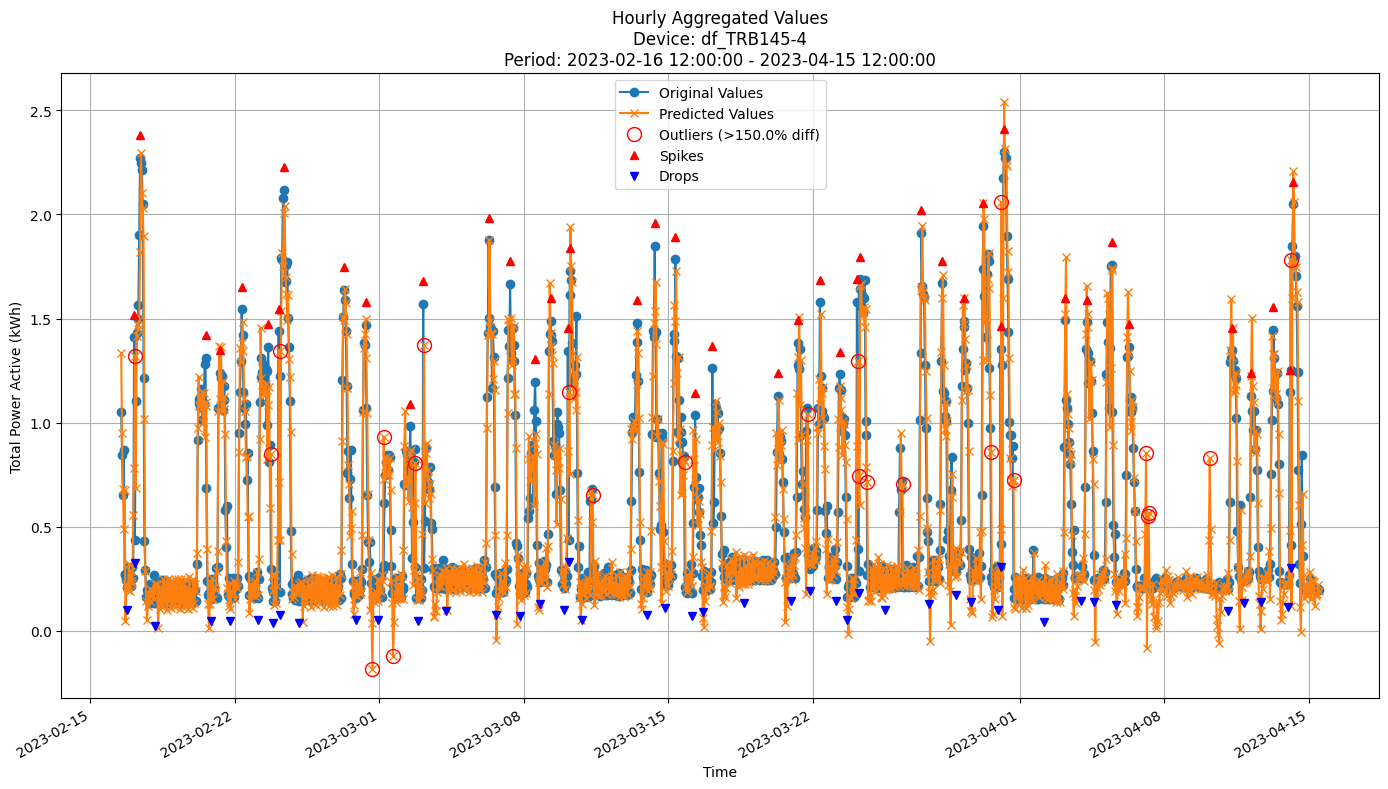


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2014
MAE: 0.1260
MAPE: 32.3543%

Directional Metrics:
Directional Accuracy: 41.3075%
First-Diff Correlation: 0.1747

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2222
  Recall: 0.1818
  F1 Score: 0.2000
Drops:
  Precision: 0.0556
  Recall: 0.0455
  F1 Score: 0.0500

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8889
  Recall: 0.7273
  F1 Score: 0.8000
Drops:
  Precision: 0.3611
  Recall: 0.2955
  F1 Score: 0.3250


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': True}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2600
	MAE: 0.1511
	MAPE: 17.9629%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0603

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2667
	MAE: 0.1528
	MAPE: 24.0071%

Directional Metrics:
	Directional Accuracy: 37.8709%
	First-Diff Correlation: 0.2342

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2371
	MAE: 0.1401
	MAPE: 29.4535%

Directional Metrics:
	Directional Accuracy: 36.9983%
	First-Diff Correlation: 0.0275

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1825
	MAE: 0.0849
	MAPE: 15.2001%

Directional Metrics:
	Directional Accuracy: 43.6735%
	First-Diff Correlation: 0.1965

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
----

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2448 ± 0.0277
	MAE: 0.1376 ± 0.0219
	MAPE: 26.4192% ± 7.0540%

	Directional Metrics:
		Directional Accuracy: 36.9306% ± 3.1016%
		First-Diff Correlation: 0.0973 ± 0.1369

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8571 ± 0.3499
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8571 ± 0.3499
Daily Metrics:
	RMSE: 0.3645 ± 0.0980
	MAE: 0.1432 ± 0.0356
	MAPE: 1.7594% ± 0.7643%

	Directional Metrics:
		Directional Accuracy: 95.5159% ± 3.5833%
		First-Diff Correlation: 0.9987 ± 0.0013

	Immediate Detection (delta=0):


#### Validation plots

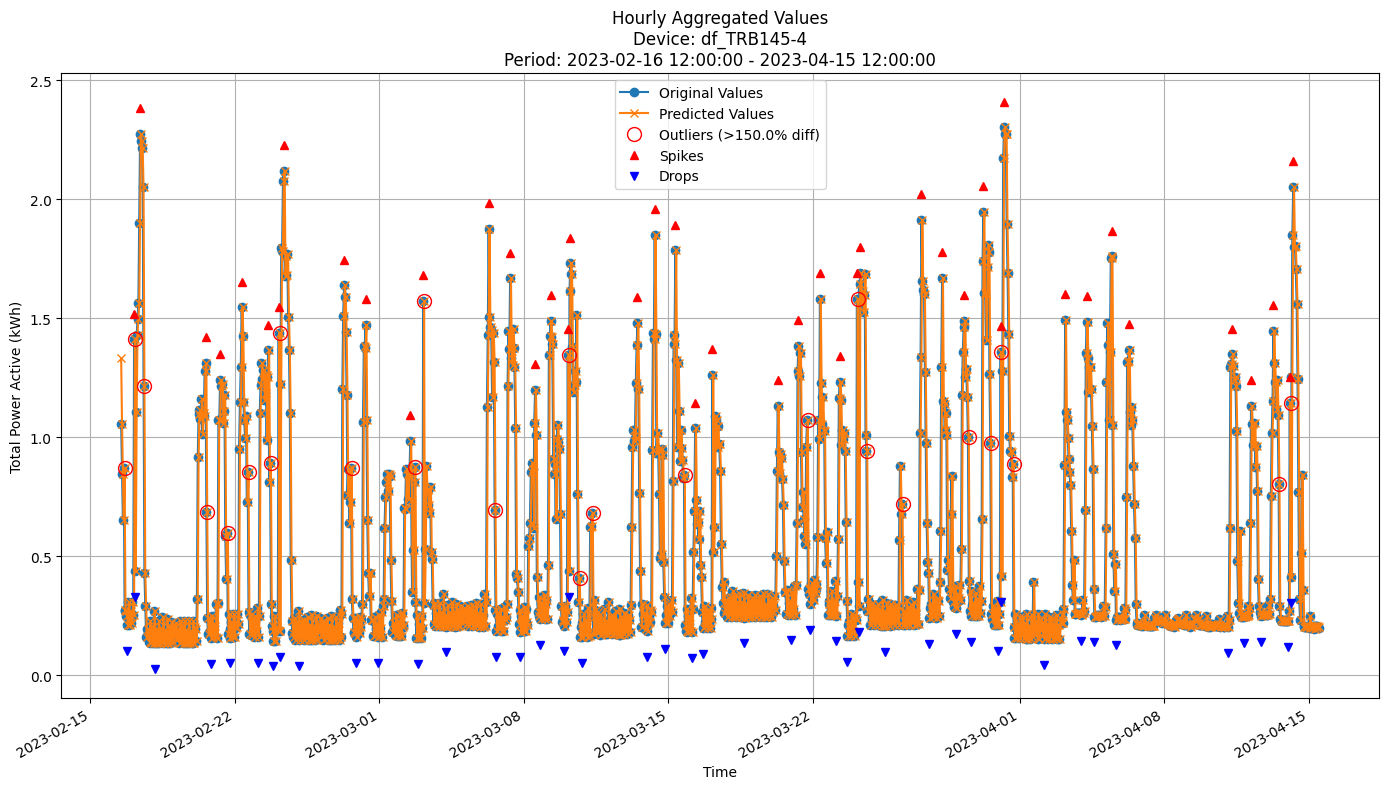


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2342
MAE: 0.1312
MAPE: 29.4605%

Directional Metrics:
Directional Accuracy: 37.3563%
First-Diff Correlation: -0.0258

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = dict(n_estimators=100, learning_rate=0.03, subsample=0.8, max_depth=10, random_state=42)

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00

Time: 1.85 seconds
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-05 13:00:00

Time: 2.96 seconds
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2678
	MAE: 0.1811
	MAPE: 26.0030%

Directional Metrics:
	Directional Accuracy: 39.3357%
	First-Diff Correlation: 0.0271

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00

Time: 4.22 seconds
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-29 10:00:00

Time: 4.97 seconds
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2378
	MAE: 0.1564
	MAPE: 29.2588%

Directional Metrics:
	Directional Accuracy: 43.9791%
	First-Diff Correlation: 0.3145

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00

Time: 13.39 seconds
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-26 09:00:00

Time: 12.87 seconds
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2039
	MAE: 0.1310
	MAPE: 29.4077%

Directional Metrics:
	Directional Accuracy: 35.4276%
	First-Diff Correlation: 0.1401

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3571
		Recall: 0.2941
		F1: 0.3226
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Sp

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00

Time: 15.21 seconds
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1572
	MAE: 0.0867
	MAPE: 19.9231%

Directional Metrics:
	Directional Accuracy: 50.6122%
	First-Diff Correlation: 0.3636

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250
	Drops:
		Precision: 0.2857
		Recall: 0.2222
		F1: 0.2500

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7778
		F1: 0.8750
	Drops:
		Precision: 0.4286
		Recall: 0.3333
		F1: 0.3750
--------------------------------------------------
Daily Metrics:
-----------

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0519 ± 0.0128
	MAE: 0.0394 ± 0.0086
	MAPE: 9.1198% ± 2.2351%

	Directional Metrics:
		Directional Accuracy: 69.4512% ± 9.0437%
		First-Diff Correlation: 0.9422 ± 0.0268

	Immediate Detection (delta=0):
		Spike Precision: 0.4383 ± 0.4058
		Spike Recall: 0.3714 ± 0.3579
		Spike F1: 0.3981 ± 0.3727
		Drop Precision: 0.0679 ± 0.0630
		Drop Recall: 0.0563 ± 0.0533
		Drop F1: 0.0610 ± 0.0569

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5399 ± 0.4699
		Spike Recall: 0.4587 ± 0.4117
		Spike F1: 0.4916 ± 0.4314
		Drop Precision: 0.1055 ± 0.1050
		Drop Recall: 0.0845 ± 0.0821
		Drop F1: 0.0928 ± 0.0902
Daily Metrics:
	RMSE: 0.1214 ± 0.0400
	MAE: 0.0882 ± 0.0304
	MAPE: 0.7558% ± 0.3167%

	Directional Metrics:
		Directional Accuracy: 95.4777% ± 1.9368%
		First-Diff Correlation: 0.9998 ± 0.0001

	Immediate Detection (delta=0):
	

#### Training plots

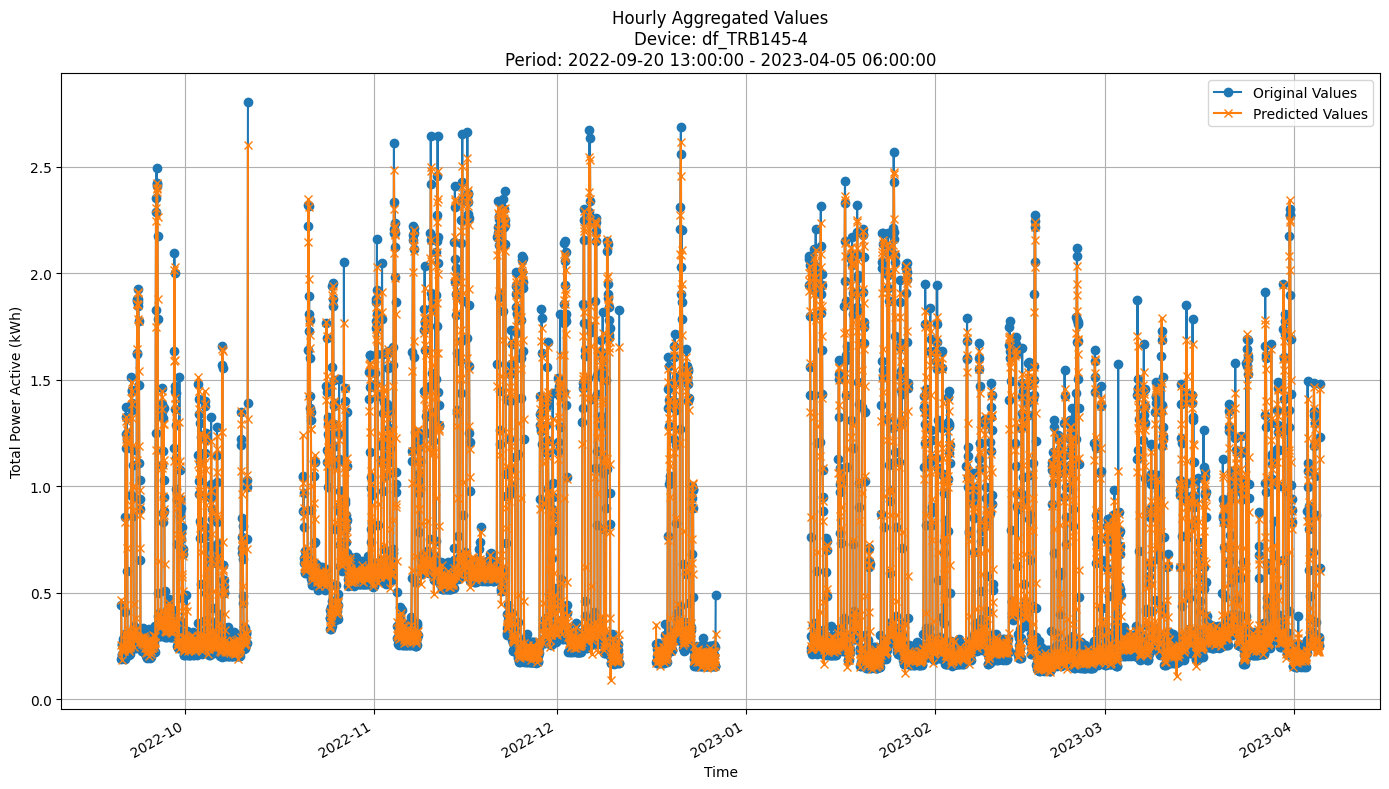


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0681
MAE: 0.0503
MAPE: 12.3426%

Directional Metrics:
Directional Accuracy: 57.6258%
First-Diff Correlation: 0.9018

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5122
  Recall: 0.4667
  F1 Score: 0.4884
Drops:
  Precision: 0.1250
  Recall: 0.1136
  F1 Score: 0.1190

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8537
  Recall: 0.7778
  F1 Score: 0.8140
Drops:
  Precision: 0.2250
  Recall: 0.2045
  F1 Score: 0.2143


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

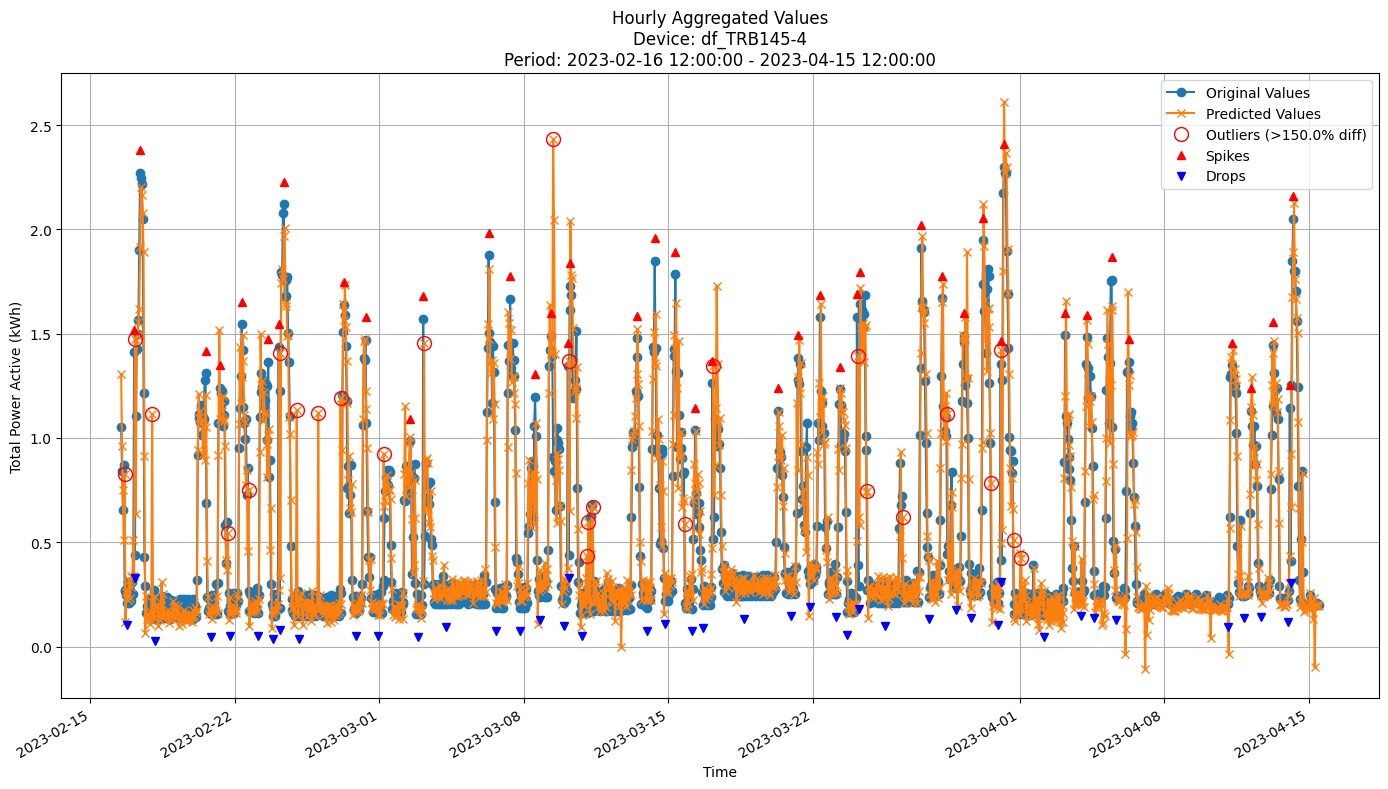


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2109
MAE: 0.1226
MAPE: 29.6343%

Directional Metrics:
Directional Accuracy: 40.4454%
First-Diff Correlation: 0.1212

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2051
  Recall: 0.1818
  F1 Score: 0.1928
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7436
  Recall: 0.6591
  F1 Score: 0.6988
Drops:
  Precision: 0.1538
  Recall: 0.1364
  F1 Score: 0.1446


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = dict(n_estimators=100, max_depth=10, max_features='sqrt', random_state=42, n_jobs=-1)

In [21]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00

Time: 0.17 seconds
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-05 13:00:00

Time: 0.26 seconds
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2315
	MAE: 0.1435
	MAPE: 18.9269%

Directional Metrics:
	Directional Accuracy: 33.2168%
	First-Diff Correlation: 0.0300

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.0714
		F1: 0.0741
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00

Time: 0.34 seconds
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-29 10:00:00

Time: 0.28 seconds
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2169
	MAE: 0.1395
	MAPE: 25.8141%

Directional Metrics:
	Directional Accuracy: 37.6963%
	First-Diff Correlation: 0.3449

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00

Time: 0.70 seconds
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-26 09:00:00

Time: 1.05 seconds
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1997
	MAE: 0.1240
	MAPE: 28.0177%

Directional Metrics:
	Directional Accuracy: 35.6021%
	First-Diff Correlation: 0.0959

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3846
		Recall: 0.2941
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00

Time: 0.95 seconds
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1470
	MAE: 0.0736
	MAPE: 15.5657%

Directional Metrics:
	Directional Accuracy: 46.1224%
	First-Diff Correlation: 0.3499

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250
	Drops:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7778
		F1: 0.8750
	Drops:
		Precision: 0.4286
		Recall: 0.3333
		F1: 0.3750
--------------------------------------------------
Daily Metrics:
------------

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1188 ± 0.0128
	MAE: 0.0765 ± 0.0079
	MAPE: 15.3973% ± 2.2847%

	Directional Metrics:
		Directional Accuracy: 44.0974% ± 6.6251%
		First-Diff Correlation: 0.6759 ± 0.0617

	Immediate Detection (delta=0):
		Spike Precision: 0.1368 ± 0.1757
		Spike Recall: 0.1143 ± 0.1772
		Spike F1: 0.1225 ± 0.1762
		Drop Precision: 0.0434 ± 0.0520
		Drop Recall: 0.0330 ± 0.0387
		Drop F1: 0.0372 ± 0.0438

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5279 ± 0.4608
		Spike Recall: 0.3778 ± 0.3622
		Spike F1: 0.4319 ± 0.3900
		Drop Precision: 0.0804 ± 0.0937
		Drop Recall: 0.0649 ± 0.0809
		Drop F1: 0.0711 ± 0.0854
Daily Metrics:
	RMSE: 0.3064 ± 0.0455
	MAE: 0.2190 ± 0.0346
	MAPE: 1.8170% ± 0.3478%

	Directional Metrics:
		Directional Accuracy: 94.7890% ± 0.4931%
		First-Diff Correlation: 0.9991 ± 0.0003

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

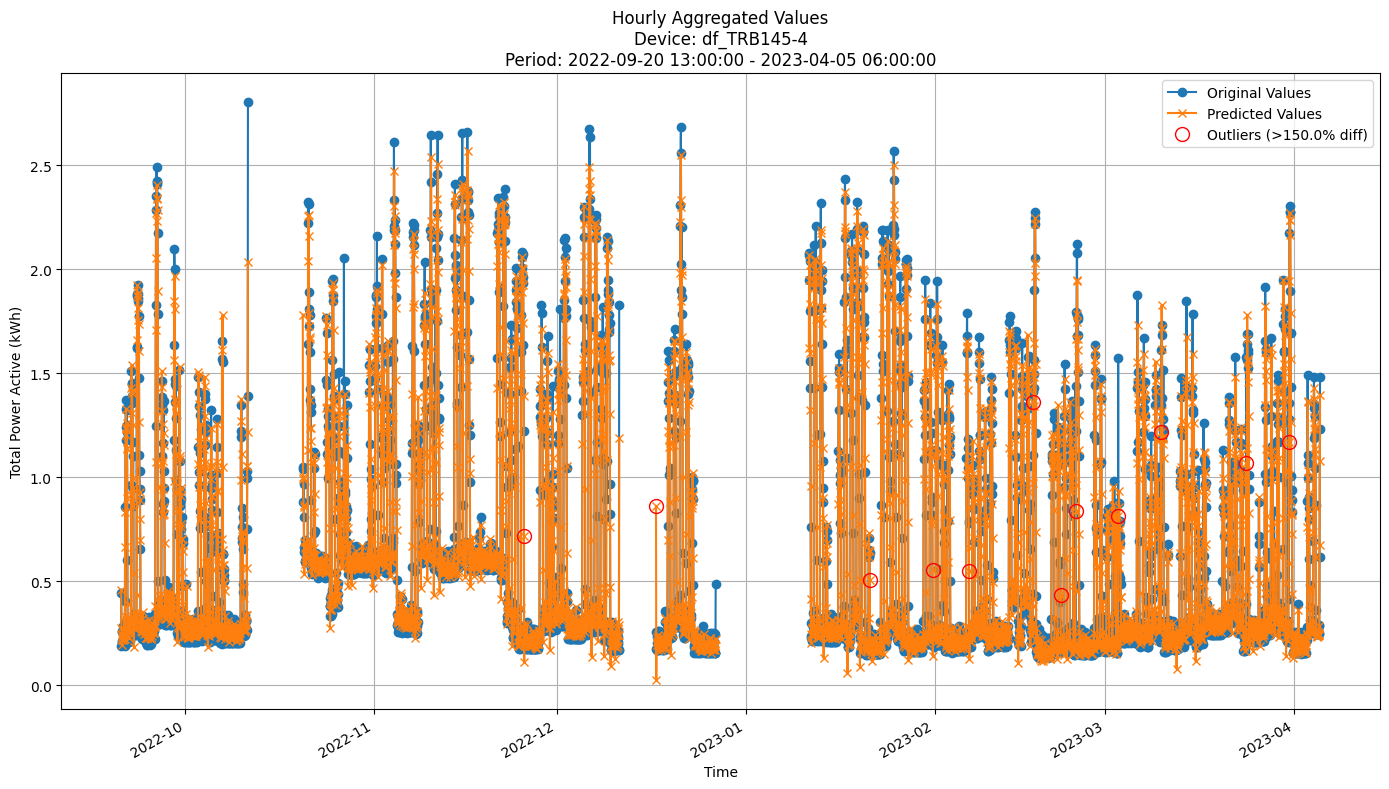


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1346
MAE: 0.0853
MAPE: 18.5684%

Directional Metrics:
Directional Accuracy: 39.1185%
First-Diff Correlation: 0.5820

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1765
  Recall: 0.1333
  F1 Score: 0.1519
Drops:
  Precision: 0.1212
  Recall: 0.0909
  F1 Score: 0.1039

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8529
  Recall: 0.6444
  F1 Score: 0.7342
Drops:
  Precision: 0.1818
  Recall: 0.1364
  F1 Score: 0.1558


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

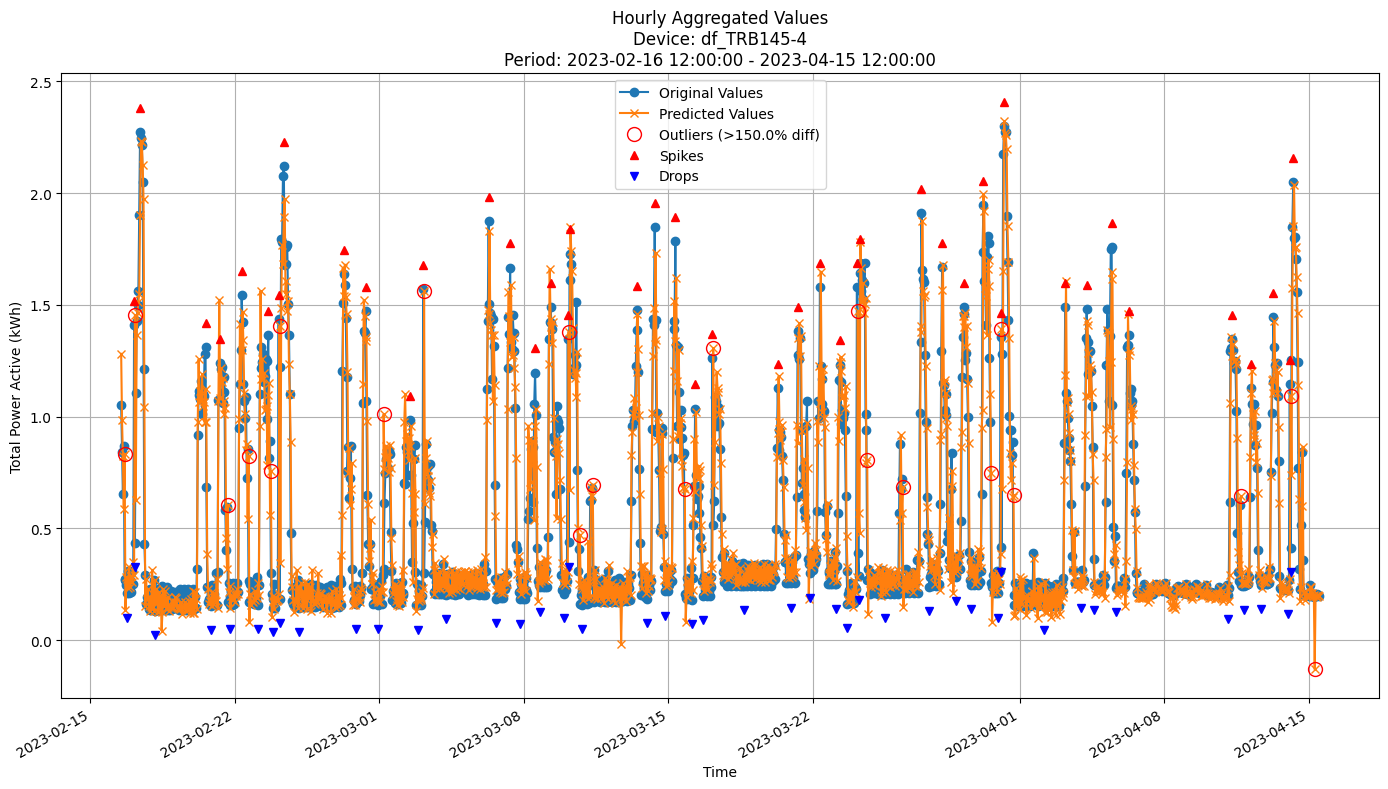


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1978
MAE: 0.1146
MAPE: 27.4537%

Directional Metrics:
Directional Accuracy: 37.4282%
First-Diff Correlation: 0.0992

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1892
  Recall: 0.1591
  F1 Score: 0.1728
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8919
  Recall: 0.7500
  F1 Score: 0.8148
Drops:
  Precision: 0.2432
  Recall: 0.2045
  F1 Score: 0.2222


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = dict(max_depth=10, grace_period=10, delta=0.5, tau=0.05, leaf_prediction="mean")


In [26]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 1.992241 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2617
	MAE: 0.1565
	MAPE: 19.7407%

Directional Metrics:
	Directional Accuracy: 37.0629%
	First-Diff Correlation: -0.0431

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7143
		F1: 0.8333
	Drops:
		Precision: 0.2727
		Recall: 0.2143
		F1: 0.2400
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 3.380684 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2536
	MAE: 0.1590
	MAPE: 26.9909%

Directional Metrics:
	Directional Accuracy: 44.1536%
	First-Diff Correlation: 0.2652

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 4.949402 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2244
	MAE: 0.1419
	MAPE: 32.9030%

Directional Metrics:
	Directional Accuracy: 41.3613%
	First-Diff Correlation: 0.0745

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4545
		Recall: 0.2941
		F1: 0.3571
	Drops:
		Precision: 0.0909
		Recall: 0.0588
		F1: 0.0714

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.6471
		F1: 0.7857
	Drops:
		Precision: 0.2727
		Recall: 0.1765
		F1: 0.2143
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 5.614311 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1777
	MAE: 0.0953
	MAPE: 22.7477%

Directional Metrics:
	Directional Accuracy: 49.7959%
	First-Diff Correlation: 0.2057

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.2222
		F1: 0.2353
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8750
		Recall: 0.7778
		F1: 0.8235
	Drops:
		Precision: 0.2857
		Recall: 0.2222
		F1: 0.2500
--------------------------------------------------
Daily Metrics:
----

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2350 ± 0.0054
	MAE: 0.1404 ± 0.0038
	MAPE: 26.9765% ± 2.2635%

	Directional Metrics:
		Directional Accuracy: 39.8336% ± 0.9191%
		First-Diff Correlation: 0.1492 ± 0.0502

	Immediate Detection (delta=0):
		Spike Precision: 0.0224 ± 0.0395
		Spike Recall: 0.0175 ± 0.0313
		Spike F1: 0.0196 ± 0.0349
		Drop Precision: 0.0108 ± 0.0178
		Drop Recall: 0.0082 ± 0.0133
		Drop F1: 0.0093 ± 0.0152

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4798 ± 0.4334
		Spike Recall: 0.2159 ± 0.2360
		Spike F1: 0.2681 ± 0.2780
		Drop Precision: 0.0875 ± 0.1014
		Drop Recall: 0.0559 ± 0.0710
		Drop F1: 0.0665 ± 0.0808
Daily Metrics:
	RMSE: 0.7877 ± 0.0765
	MAE: 0.5436 ± 0.0649
	MAPE: 5.1468% ± 0.6909%

	Directional Metrics:
		Directional Accuracy: 92.5249% ± 1.5856%
		First-Diff Correlation: 0.9933 ± 0.0022

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

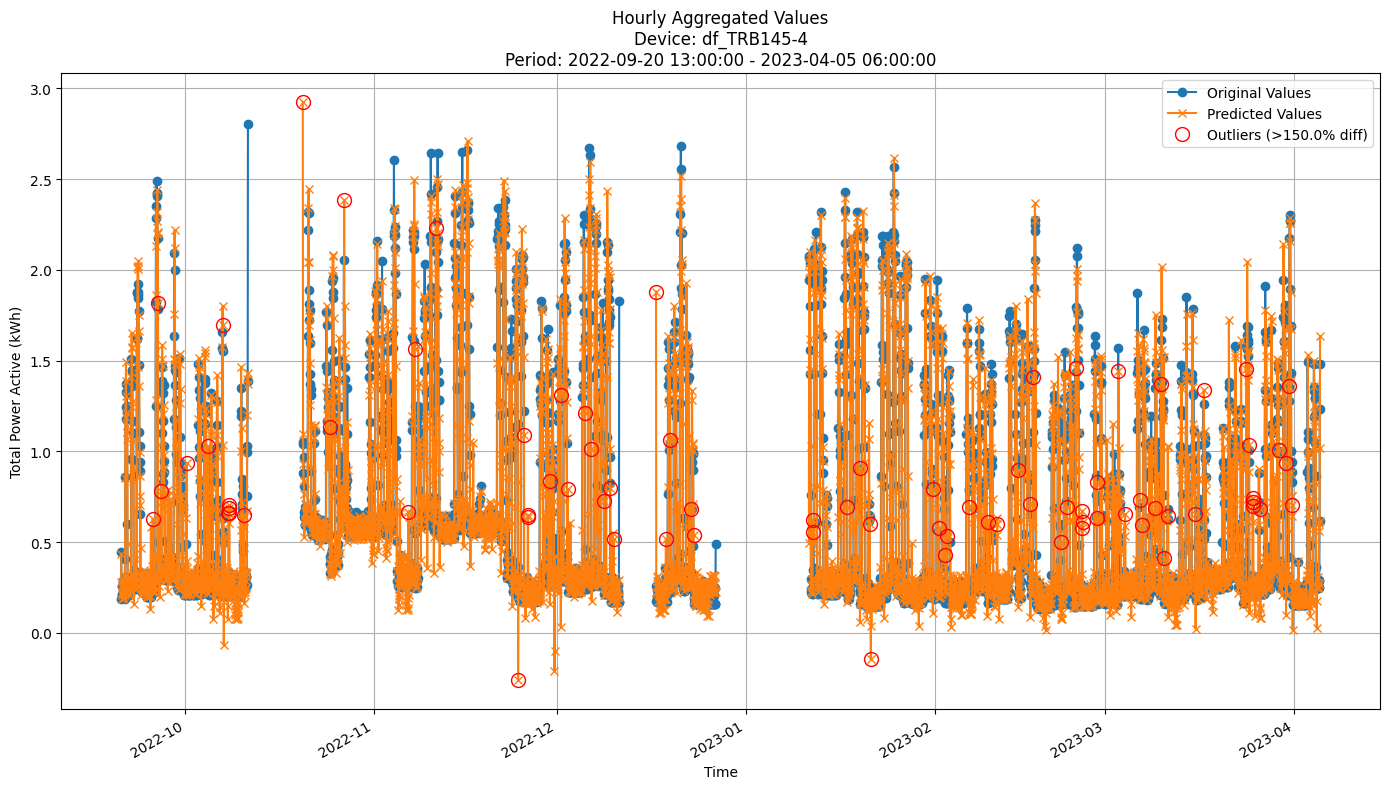


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2300
MAE: 0.1384
MAPE: 29.2823%

Directional Metrics:
Directional Accuracy: 40.3706%
First-Diff Correlation: 0.1663

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1111
  Recall: 0.0889
  F1 Score: 0.0988
Drops:
  Precision: 0.0278
  Recall: 0.0227
  F1 Score: 0.0250

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7222
  Recall: 0.5778
  F1 Score: 0.6420
Drops:
  Precision: 0.2222
  Recall: 0.1818
  F1 Score: 0.2000


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

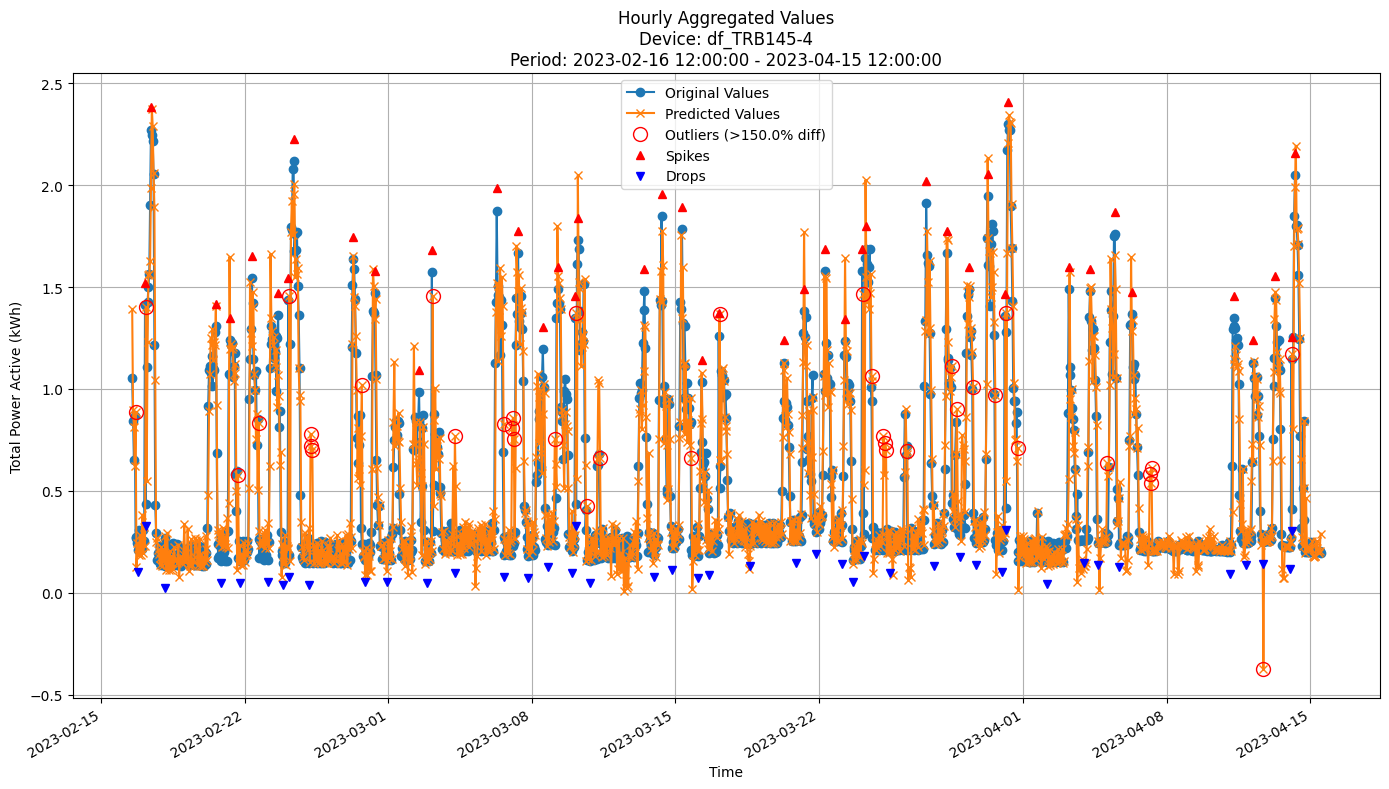


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2278
MAE: 0.1370
MAPE: 34.1265%

Directional Metrics:
Directional Accuracy: 41.8822%
First-Diff Correlation: 0.0366

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3143
  Recall: 0.2500
  F1 Score: 0.2785
Drops:
  Precision: 0.0286
  Recall: 0.0227
  F1 Score: 0.0253

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.6364
  F1 Score: 0.7089
Drops:
  Precision: 0.3714
  Recall: 0.2955
  F1 Score: 0.3291


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)


In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 11.679817 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2463
	MAE: 0.1454
	MAPE: 17.8418%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0439

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7857
		F1: 0.8800
	Drops:
		Precision: 0.5455
		Recall: 0.4286
		F1: 0.4800
--------------------------------------------------
Daily Metrics:
--

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 14.778236 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2406
	MAE: 0.1412
	MAPE: 23.1135%

Directional Metrics:
	Directional Accuracy: 36.6492%
	First-Diff Correlation: 0.2719

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 23.658234 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2109
	MAE: 0.1275
	MAPE: 28.4906%

Directional Metrics:
	Directional Accuracy: 38.9180%
	First-Diff Correlation: 0.0341

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1875
		Recall: 0.1765
		F1: 0.1818
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9412
		F1: 0.9697
	Drops:
		Precision: 0.5625
		Recall: 0.5294
		F1: 0.5455
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 24.578751 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1581
	MAE: 0.0778
	MAPE: 15.4396%

Directional Metrics:
	Directional Accuracy: 52.2449%
	First-Diff Correlation: 0.2390

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2222
		Recall: 0.2222
		F1: 0.2222
	Drops:
		Precision: 0.1111
		Recall: 0.1111
		F1: 0.1111

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
--------------------------------------------------
Daily Metrics:
---

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2214 ± 0.0051
	MAE: 0.1283 ± 0.0027
	MAPE: 23.6472% ± 1.7258%

	Directional Metrics:
		Directional Accuracy: 35.4650% ± 1.9386%
		First-Diff Correlation: 0.1548 ± 0.0545

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5218 ± 0.4574
		Spike Recall: 0.3889 ± 0.3739
		Spike F1: 0.4344 ± 0.3944
		Drop Precision: 0.1823 ± 0.1664
		Drop Recall: 0.1428 ± 0.1479
		Drop F1: 0.1570 ± 0.1554
Daily Metrics:
	RMSE: 0.4046 ± 0.0702
	MAE: 0.2507 ± 0.0316
	MAPE: 2.4918% ± 0.3779%

	Directional Metrics:
		Directional Accuracy: 93.7104% ± 1.2541%
		First-Diff Correlation: 0.9982 ± 0.0007

	Immediate Detection (delta=0):


#### Training plots

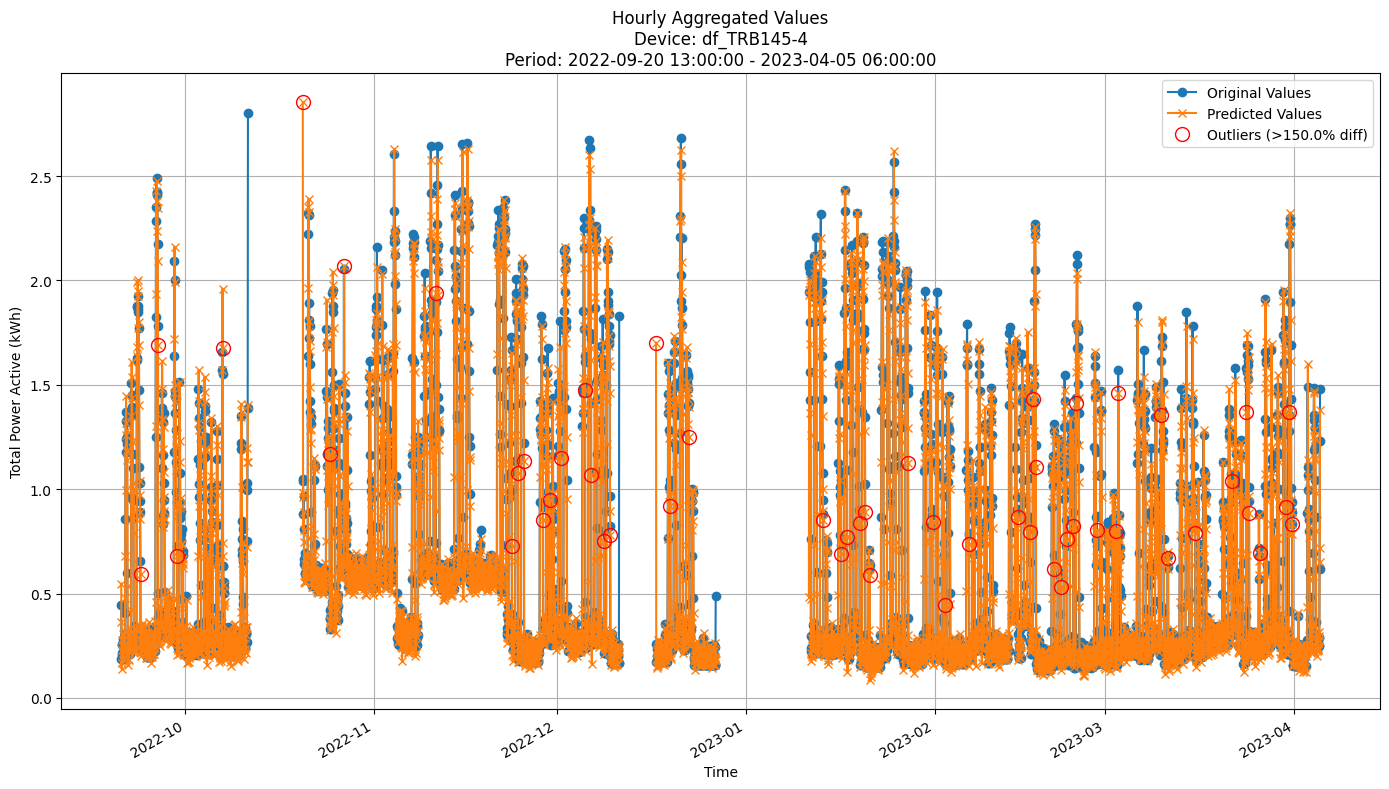


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2159
MAE: 0.1265
MAPE: 25.6550%

Directional Metrics:
Directional Accuracy: 36.3887%
First-Diff Correlation: 0.1670

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7778
  Recall: 0.6222
  F1 Score: 0.6914
Drops:
  Precision: 0.3714
  Recall: 0.2955
  F1 Score: 0.3291


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

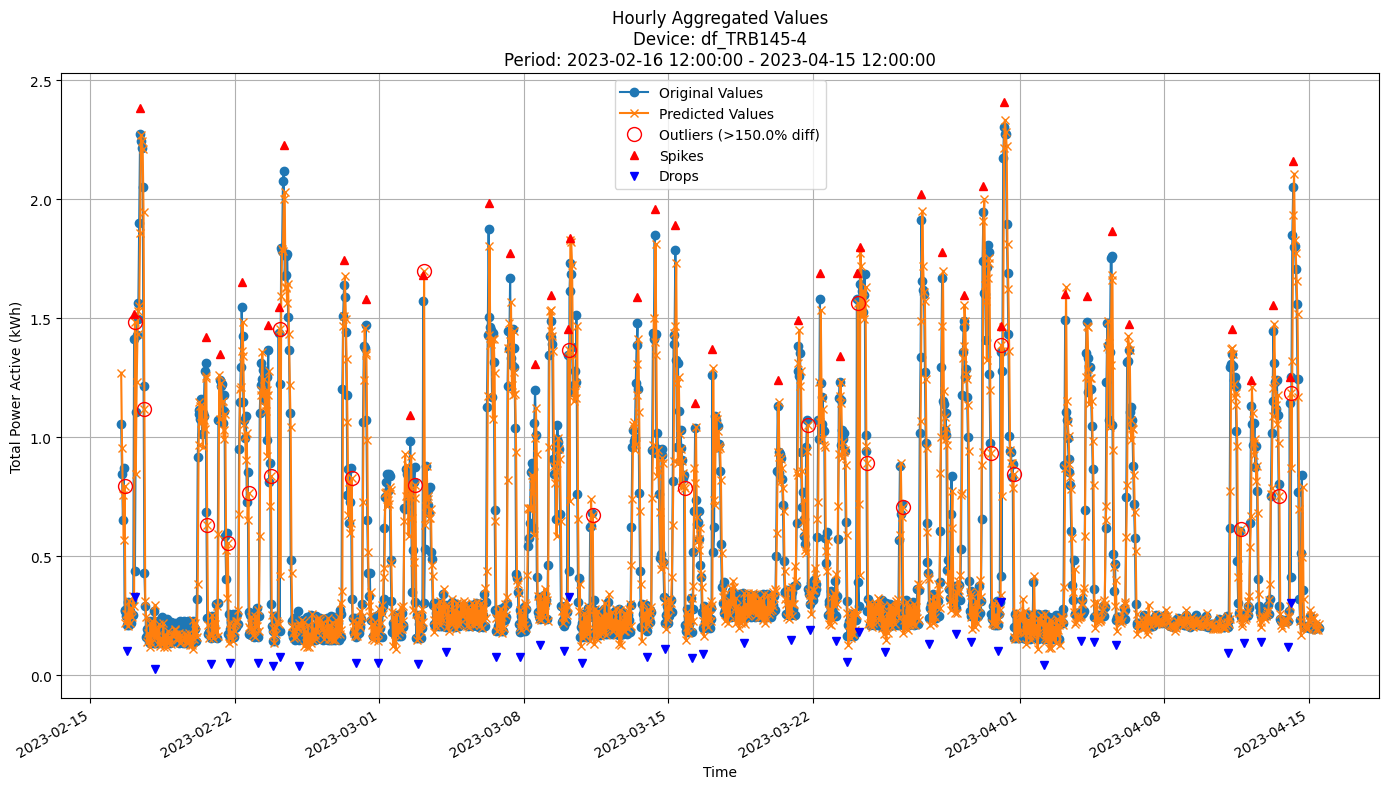


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2073
MAE: 0.1185
MAPE: 27.7761%

Directional Metrics:
Directional Accuracy: 40.0144%
First-Diff Correlation: 0.0193

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1538
  Recall: 0.1364
  F1 Score: 0.1446
Drops:
  Precision: 0.0256
  Recall: 0.0227
  F1 Score: 0.0241

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9744
  Recall: 0.8636
  F1 Score: 0.9157
Drops:
  Precision: 0.4615
  Recall: 0.4091
  F1 Score: 0.4337


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [38]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [39]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.025406 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2606
	MAE: 0.1517
	MAPE: 18.0476%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0592

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.026848 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2541
	MAE: 0.1555
	MAPE: 26.5193%

Directional Metrics:
	Directional Accuracy: 39.0925%
	First-Diff Correlation: 0.2278

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 0.266624 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2627
	MAE: 0.1601
	MAPE: 35.4773%

Directional Metrics:
	Directional Accuracy: 40.8377%
	First-Diff Correlation: 0.0160

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1765
		F1: 0.1875
	Drops:
		Precision: 0.0714
		Recall: 0.0588
		F1: 0.0645

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9333
		Recall: 0.8235
		F1: 0.8750
	Drops:
		Precision: 0.7143
		Recall: 0.5882
		F1: 0.6452
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 0.488914 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1643
	MAE: 0.0891
	MAPE: 19.6800%

Directional Metrics:
	Directional Accuracy: 45.3061%
	First-Diff Correlation: 0.2221

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.1111
		F1: 0.1176
	Drops:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.8889
		F1: 0.9412
	Drops:
		Precision: 0.5714
		Recall: 0.4444
		F1: 0.5000
--------------------------------------------------
Daily Metrics:
----

#### Results

In [40]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2443 ± 0.0053
	MAE: 0.1461 ± 0.0062
	MAPE: 27.7853% ± 2.3922%

	Directional Metrics:
		Directional Accuracy: 36.1282% ± 2.0636%
		First-Diff Correlation: 0.0998 ± 0.0564

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5163 ± 0.4518
		Spike Recall: 0.4175 ± 0.4424
		Spike F1: 0.4294 ± 0.4304
		Drop Precision: 0.2657 ± 0.3556
		Drop Recall: 0.2002 ± 0.3431
		Drop F1: 0.2125 ± 0.3420
Daily Metrics:
	RMSE: 0.7115 ± 0.2895
	MAE: 0.4614 ± 0.2369
	MAPE: 4.3231% ± 1.9738%

	Directional Metrics:
		Directional Accuracy: 95.7792% ± 3.1857%
		First-Diff Correlation: 0.9944 ± 0.0057

	Immediate Detection (delta=0):


#### Training plots


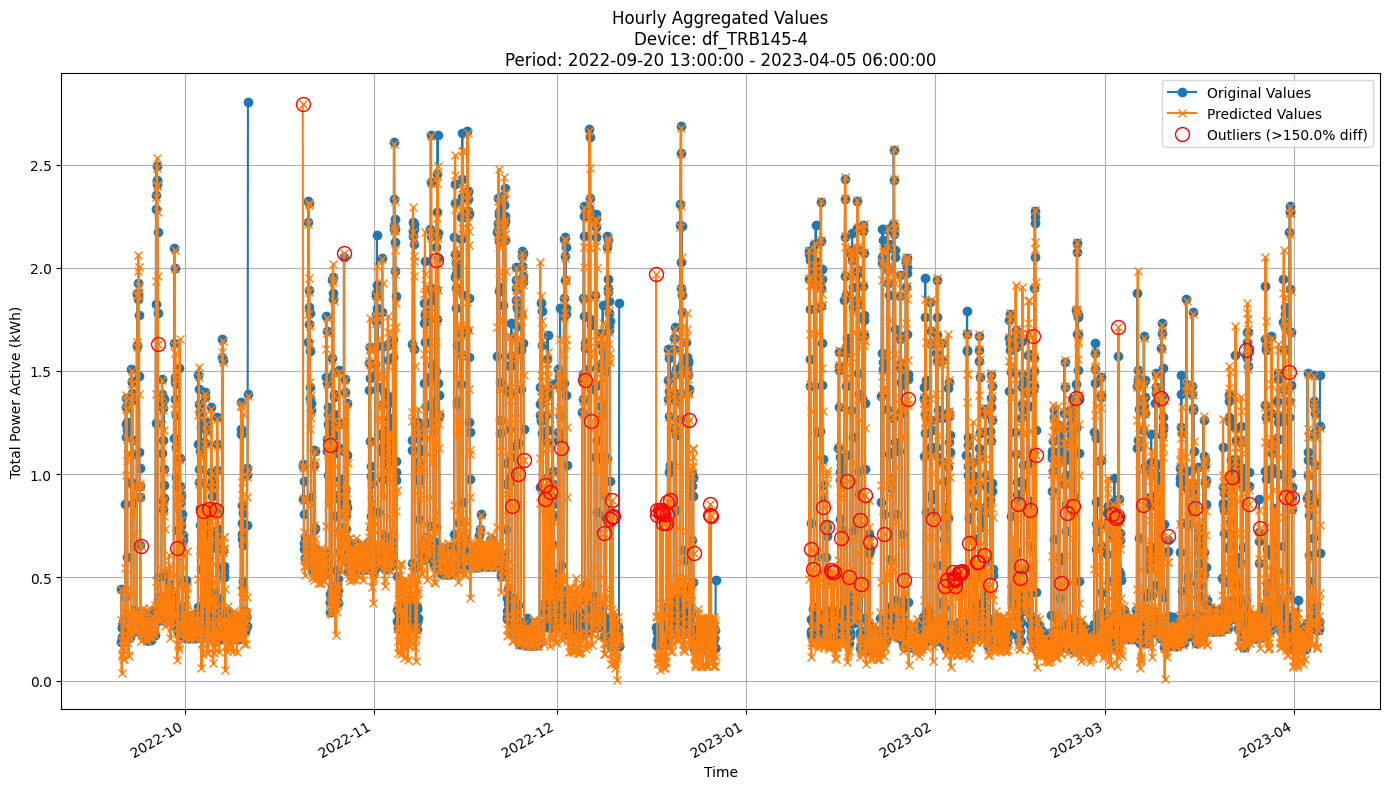


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2419
MAE: 0.1480
MAPE: 32.1577%

Directional Metrics:
Directional Accuracy: 39.1936%
First-Diff Correlation: 0.0974

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8750
  Recall: 0.1556
  F1 Score: 0.2642
Drops:
  Precision: 0.5000
  Recall: 0.0909
  F1 Score: 0.1538


In [41]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

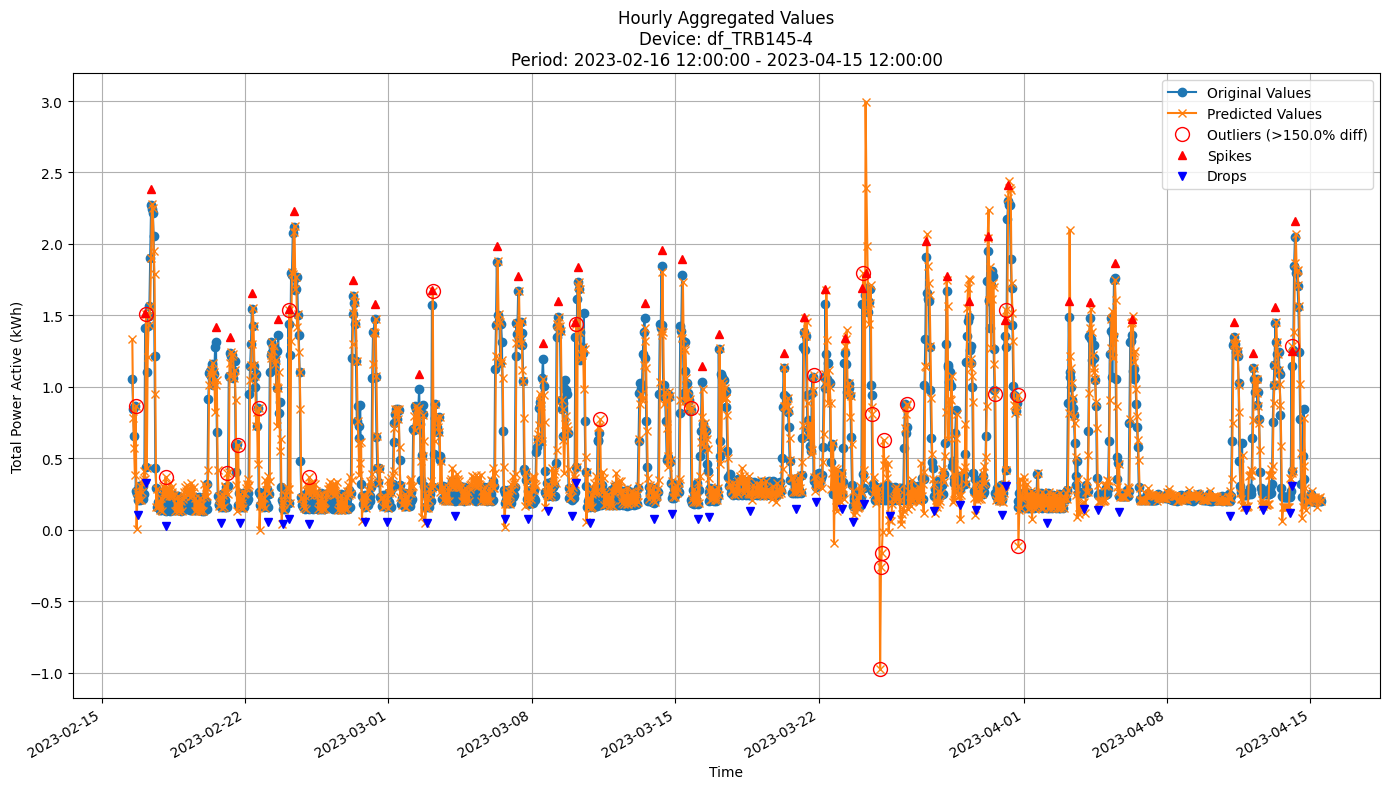


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2386
MAE: 0.1411
MAPE: 34.7616%

Directional Metrics:
Directional Accuracy: 39.5833%
First-Diff Correlation: -0.0229

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1026
  Recall: 0.0909
  F1 Score: 0.0964
Drops:
  Precision: 0.0513
  Recall: 0.0455
  F1 Score: 0.0482

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9231
  Recall: 0.8182
  F1 Score: 0.8675
Drops:
  Precision: 0.4872
  Recall: 0.4318
  F1 Score: 0.4578


In [42]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### xFastODT

In [43]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

xfodt = xfastodt.xFastODT

xfodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [44]:
xfodt_all_train_preds, xfodt_all_valid_preds, \
xfodt_all_train_metrics, xfodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=xfodt, 
    model_params=xfodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.029884 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2604
	MAE: 0.1513
	MAPE: 17.9753%

Directional Metrics:
	Directional Accuracy: 33.3916%
	First-Diff Correlation: -0.0592

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0714
		Recall: 0.0714
		F1: 0.0714

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.031296 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2541
	MAE: 0.1555
	MAPE: 26.5193%

Directional Metrics:
	Directional Accuracy: 39.0925%
	First-Diff Correlation: 0.2278

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 46.958313 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3128
	MAE: 0.1962
	MAPE: 45.0742%

Directional Metrics:
	Directional Accuracy: 43.1065%
	First-Diff Correlation: 0.0747

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1111
		Recall: 0.0588
		F1: 0.0769
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7778
		Recall: 0.4118
		F1: 0.5385
	Drops:
		Precision: 0.2222
		Recall: 0.1176
		F1: 0.1538
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 63.805702 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2160
	MAE: 0.1312
	MAPE: 32.8180%

Directional Metrics:
	Directional Accuracy: 40.0000%
	First-Diff Correlation: 0.2718

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1111
		F1: 0.1429
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8000
		Recall: 0.4444
		F1: 0.5714
	Drops:
		Precision: 0.2000
		Recall: 0.1111
		F1: 0.1429
--------------------------------------------------
Daily Metrics:
---

#### Results

In [45]:
print("\n\nTrain period metrics:")
xfodt_all_time_train_metrics = all_time_aggregation_metrics(xfodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
xfodt_all_time_valid_metrics = all_time_aggregation_metrics(xfodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2534 ± 0.0244
	MAE: 0.1388 ± 0.0213
	MAPE: 25.2572% ± 3.5091%

	Directional Metrics:
		Directional Accuracy: 47.3609% ± 12.0640%
		First-Diff Correlation: 0.2065 ± 0.1468

	Immediate Detection (delta=0):
		Spike Precision: 0.0743 ± 0.1078
		Spike Recall: 0.0746 ± 0.1207
		Spike F1: 0.0739 ± 0.1136
		Drop Precision: 0.0197 ± 0.0348
		Drop Recall: 0.0212 ± 0.0396
		Drop F1: 0.0203 ± 0.0370

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3982 ± 0.3705
		Spike Recall: 0.3762 ± 0.3655
		Spike F1: 0.3848 ± 0.3656
		Drop Precision: 0.1909 ± 0.3384
		Drop Recall: 0.1918 ± 0.3388
		Drop F1: 0.1911 ± 0.3385
Daily Metrics:
	RMSE: 0.9733 ± 0.4178
	MAE: 0.5873 ± 0.2975
	MAPE: 4.8393% ± 2.2299%

	Directional Metrics:
		Directional Accuracy: 92.7765% ± 5.6730%
		First-Diff Correlation: 0.9858 ± 0.0110

	Immediate Detection (delta=0):

#### Training plots


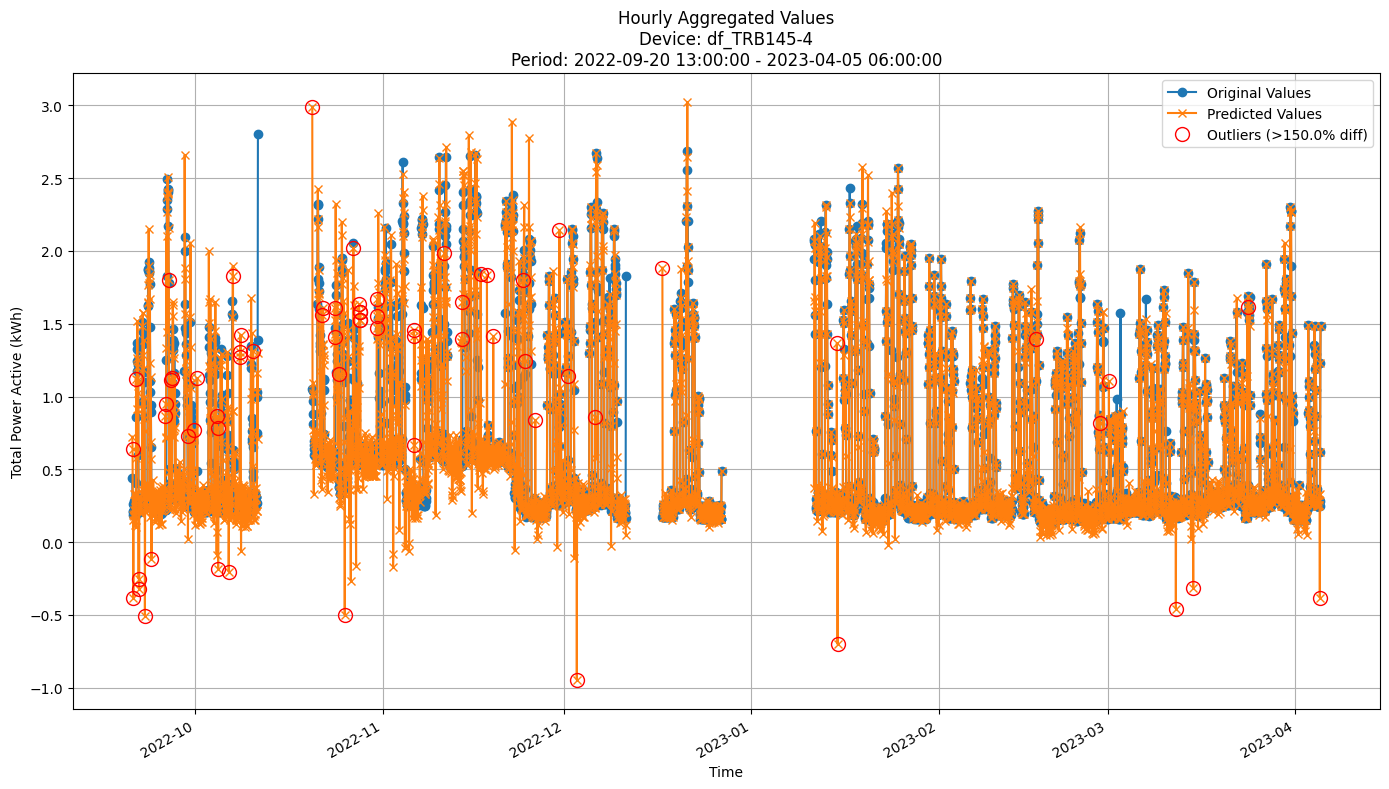


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2228
MAE: 0.0982
MAPE: 18.8324%

Directional Metrics:
Directional Accuracy: 66.5164%
First-Diff Correlation: 0.4437

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3137
  Recall: 0.3556
  F1 Score: 0.3333
Drops:
  Precision: 0.0980
  Recall: 0.1136
  F1 Score: 0.1053

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5882
  Recall: 0.6667
  F1 Score: 0.6250
Drops:
  Precision: 0.1765
  Recall: 0.2045
  F1 Score: 0.1895


In [46]:
for device_id in xfodt_all_train_preds.keys():
    y_train = xfodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = xfodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

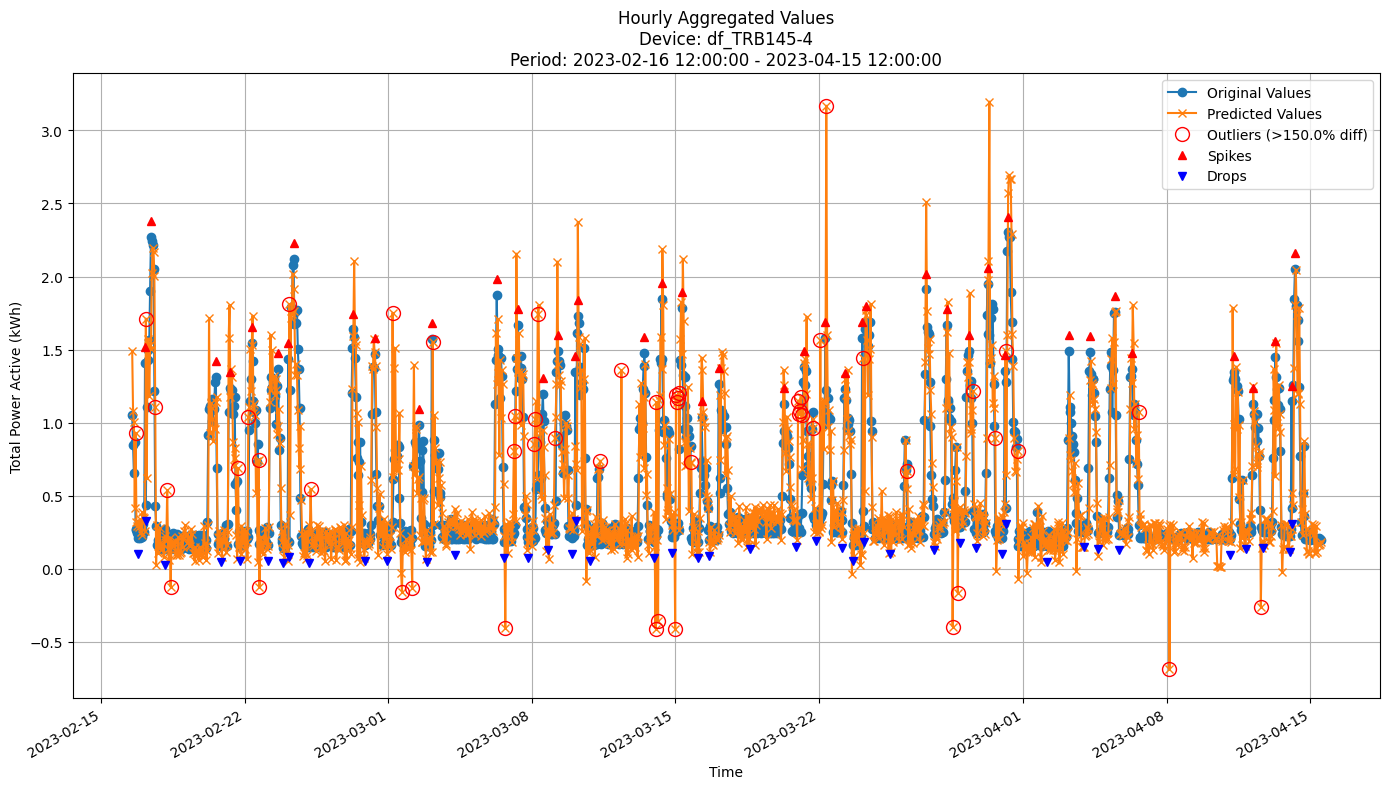


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2930
MAE: 0.1786
MAPE: 43.0310%

Directional Metrics:
Directional Accuracy: 41.2356%
First-Diff Correlation: 0.0465

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0606
  Recall: 0.0455
  F1 Score: 0.0519
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.5000
  F1 Score: 0.5714
Drops:
  Precision: 0.2812
  Recall: 0.2045
  F1 Score: 0.2368


In [47]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in xfodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, xfodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, xfodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [48]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [49]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 366.392860 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3094
	MAE: 0.1831
	MAPE: 23.6638%

Directional Metrics:
	Directional Accuracy: 46.1538%
	First-Diff Correlation: -0.0548

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.0714
		F1: 0.0909
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 0.4286
		F1: 0.5455
	Drops:
		Precision: 0.1429
		Recall: 0.0714
		F1: 0.0952
--------------------------------------------------
Daily Metrics:
-

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 561.748634 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2639
	MAE: 0.1724
	MAPE: 30.3204%

Directional Metrics:
	Directional Accuracy: 47.2949%
	First-Diff Correlation: 0.2738

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 1300.058823 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2533
	MAE: 0.1636
	MAPE: 39.6162%

Directional Metrics:
	Directional Accuracy: 45.3752%
	First-Diff Correlation: 0.0386

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1765
		F1: 0.1875
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8667
		Recall: 0.7647
		F1: 0.8125
	Drops:
		Precision: 0.2000
		Recall: 0.1765
		F1: 0.1875
--------------------------------------------------
Daily Metrics:
-

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 1327.468727 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2254
	MAE: 0.1364
	MAPE: 40.9422%

Directional Metrics:
	Directional Accuracy: 55.1020%
	First-Diff Correlation: 0.4438

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1667
		Recall: 0.1111
		F1: 0.1333

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.2222
		F1: 0.2667
	Drops:
		Precision: 0.1667
		Recall: 0.1111
		F1: 0.1333
--------------------------------------------------
Daily Metrics:
-

#### Results

In [50]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1801 ± 0.0150
	MAE: 0.0744 ± 0.0131
	MAPE: 14.8861% ± 3.9173%

	Directional Metrics:
		Directional Accuracy: 75.2814% ± 5.5444%
		First-Diff Correlation: 0.5734 ± 0.0544

	Immediate Detection (delta=0):
		Spike Precision: 0.1974 ± 0.1891
		Spike Recall: 0.2032 ± 0.1996
		Spike F1: 0.1986 ± 0.1918
		Drop Precision: 0.0628 ± 0.0613
		Drop Recall: 0.0661 ± 0.0673
		Drop F1: 0.0638 ± 0.0636

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3371 ± 0.3016
		Spike Recall: 0.3429 ± 0.3012
		Spike F1: 0.3367 ± 0.2951
		Drop Precision: 0.1508 ± 0.1430
		Drop Recall: 0.1621 ± 0.1630
		Drop F1: 0.1550 ± 0.1514
Daily Metrics:
	RMSE: 0.4711 ± 0.0167
	MAE: 0.2453 ± 0.0262
	MAPE: 1.7804% ± 0.1302%

	Directional Metrics:
		Directional Accuracy: 95.3989% ± 0.8972%
		First-Diff Correlation: 0.9972 ± 0.0004

	Immediate Detection (delta=0):


#### Training plots

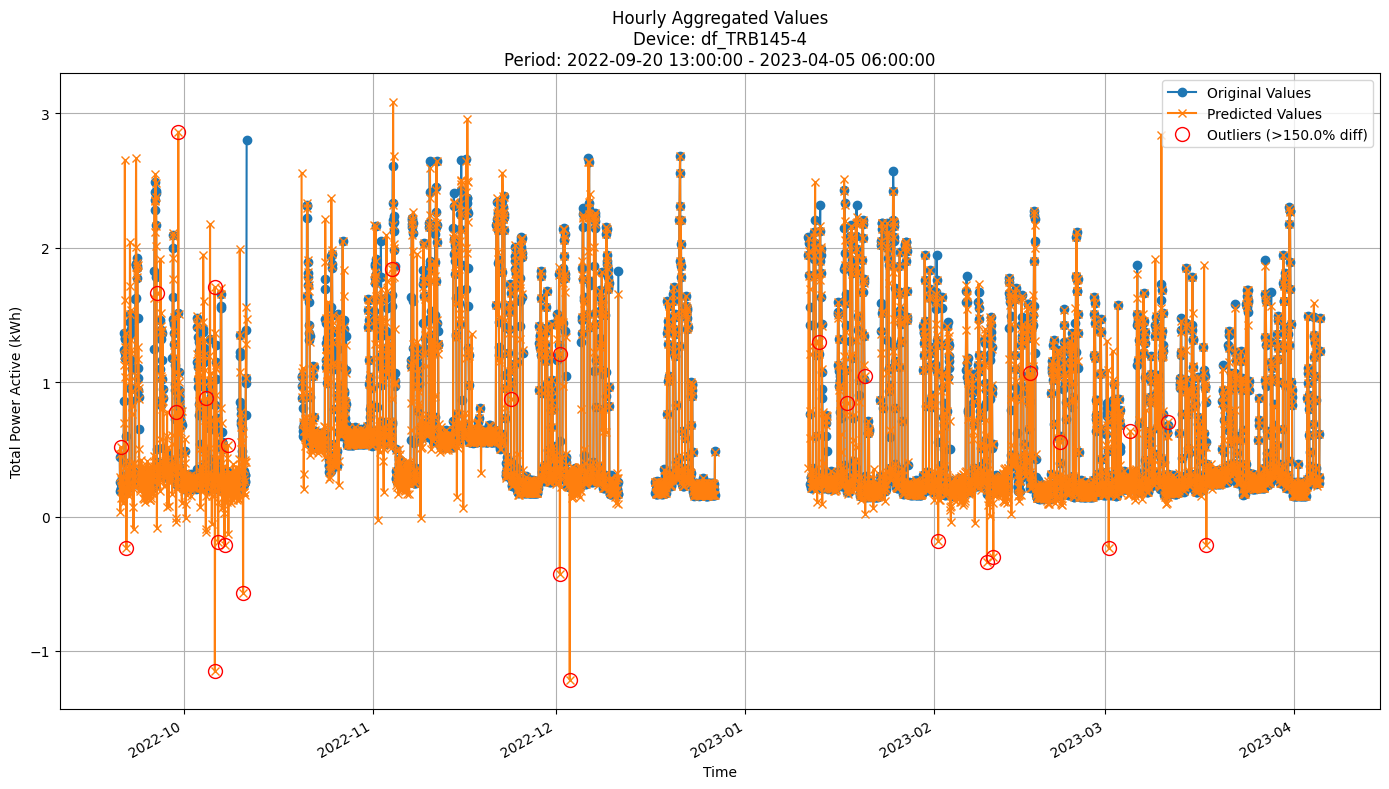


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1572
MAE: 0.0578
MAPE: 11.6581%

Directional Metrics:
Directional Accuracy: 80.5409%
First-Diff Correlation: 0.6505

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4400
  Recall: 0.4889
  F1 Score: 0.4632
Drops:
  Precision: 0.1633
  Recall: 0.1818
  F1 Score: 0.1720

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6000
  Recall: 0.6667
  F1 Score: 0.6316
Drops:
  Precision: 0.3265
  Recall: 0.3636
  F1 Score: 0.3441


In [51]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

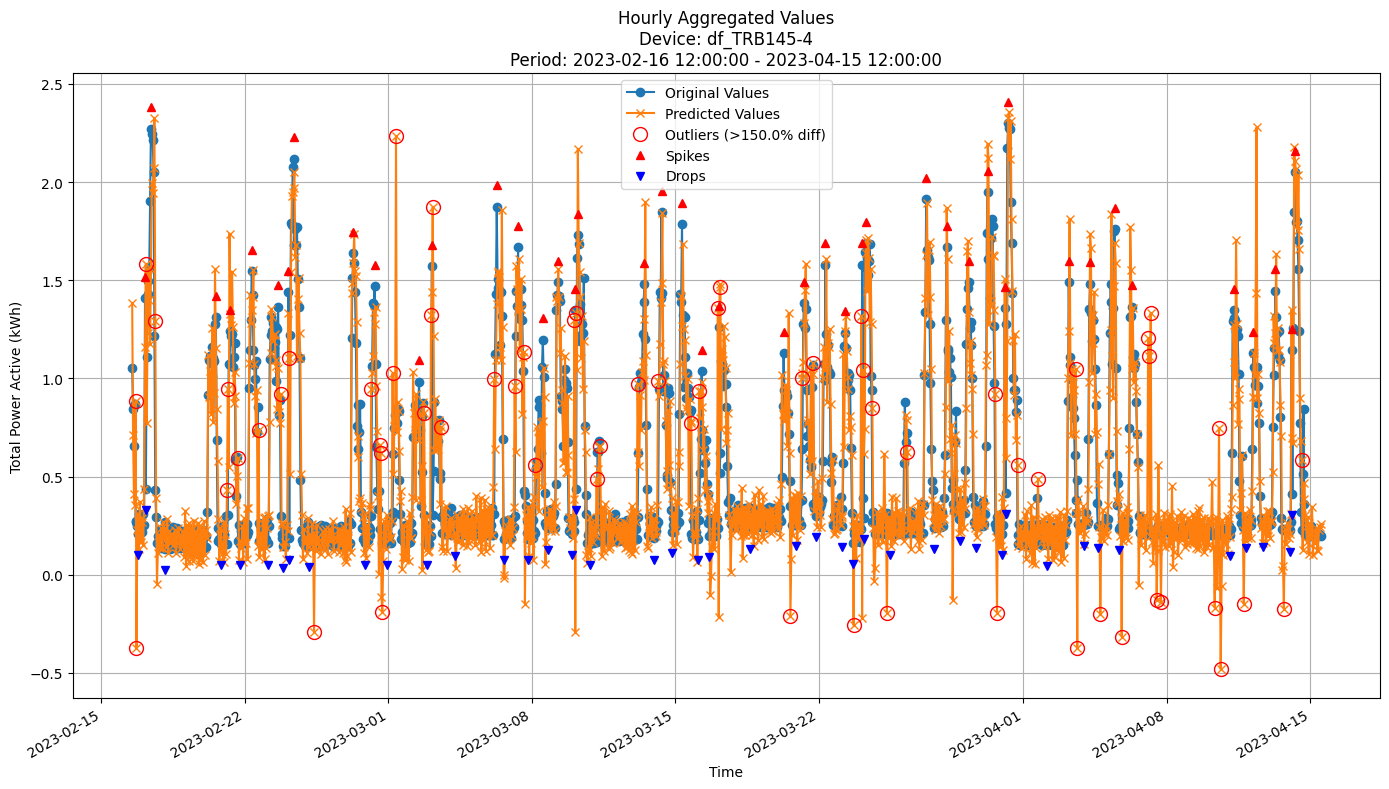


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2528
MAE: 0.1584
MAPE: 42.1365%

Directional Metrics:
Directional Accuracy: 46.6236%
First-Diff Correlation: 0.1021

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1471
  Recall: 0.1136
  F1 Score: 0.1282
Drops:
  Precision: 0.0588
  Recall: 0.0455
  F1 Score: 0.0513

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6765
  Recall: 0.5227
  F1 Score: 0.5897
Drops:
  Precision: 0.2353
  Recall: 0.1818
  F1 Score: 0.2051


In [52]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [53]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = dict(
    length=20,
    learning_rate=0.5,
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence_hf,
    eagerness=eagerness,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    max_feature=max_features,
    tie_threshold=tie_threshold,
    split_criterion='vr_rel',
    verbose=False
)

In [54]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.096550 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2587
	MAE: 0.1516
	MAPE: 18.1020%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0537

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.7143
		Recall: 0.7143
		F1: 0.7143
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.210548 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2519
	MAE: 0.1476
	MAPE: 24.3127%

Directional Metrics:
	Directional Accuracy: 38.9180%
	First-Diff Correlation: 0.2365

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 0.752480 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2256
	MAE: 0.1356
	MAPE: 30.1385%

Directional Metrics:
	Directional Accuracy: 40.1396%
	First-Diff Correlation: 0.0688

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1765
		Recall: 0.1765
		F1: 0.1765
	Drops:
		Precision: 0.0588
		Recall: 0.0588
		F1: 0.0588

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.5294
		Recall: 0.5294
		F1: 0.5294
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 7.206528 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1616
	MAE: 0.0732
	MAPE: 13.2106%

Directional Metrics:
	Directional Accuracy: 42.8571%
	First-Diff Correlation: 0.2764

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1111
		Recall: 0.1111
		F1: 0.1111

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
--------------------------------------------------
Daily Metrics:
----

#### Results

In [55]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2724 ± 0.0859
	MAE: 0.1590 ± 0.0531
	MAPE: 30.8989% ± 13.3619%

	Directional Metrics:
		Directional Accuracy: 35.4723% ± 2.4288%
		First-Diff Correlation: 0.0908 ± 0.0519

	Immediate Detection (delta=0):
		Spike Precision: 0.0039 ± 0.0095
		Spike Recall: 0.0032 ± 0.0078
		Spike F1: 0.0035 ± 0.0085
		Drop Precision: 0.0205 ± 0.0336
		Drop Recall: 0.0213 ± 0.0370
		Drop F1: 0.0207 ± 0.0350

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3961 ± 0.4611
		Spike Recall: 0.3905 ± 0.4542
		Spike F1: 0.3914 ± 0.4537
		Drop Precision: 0.2614 ± 0.3520
		Drop Recall: 0.2622 ± 0.3561
		Drop F1: 0.2609 ± 0.3531
Daily Metrics:
	RMSE: 1.2596 ± 1.6623
	MAE: 0.7589 ± 0.9925
	MAPE: 6.9353% ± 8.2166%

	Directional Metrics:
		Directional Accuracy: 95.5188% ± 4.0574%
		First-Diff Correlation: 0.9826 ± 0.0350

	Immediate Detection (delta=0):

#### Train plots

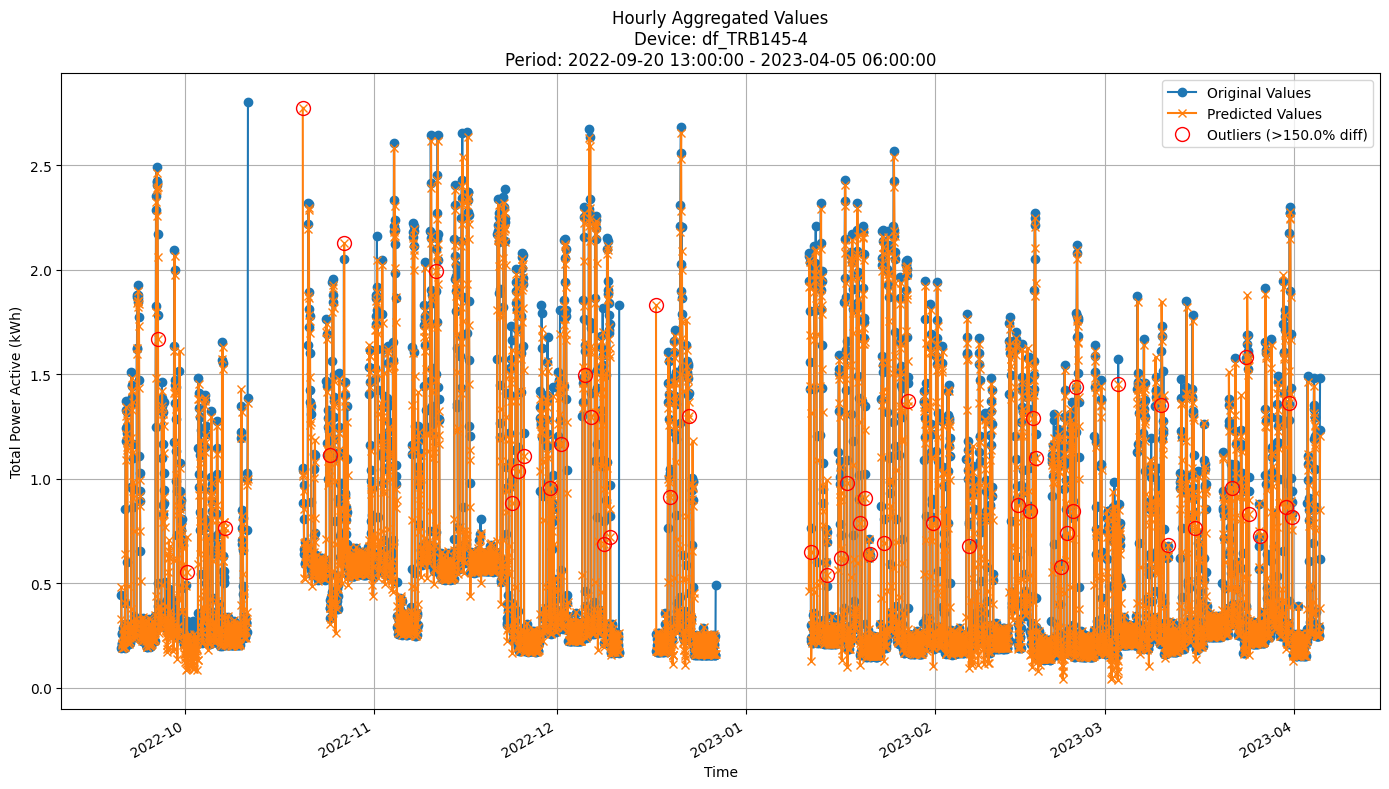


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2290
MAE: 0.1330
MAPE: 26.8009%

Directional Metrics:
Directional Accuracy: 36.7643%
First-Diff Correlation: 0.1344

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0270
  Recall: 0.0222
  F1 Score: 0.0244
Drops:
  Precision: 0.0556
  Recall: 0.0455
  F1 Score: 0.0500

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9730
  Recall: 0.8000
  F1 Score: 0.8780
Drops:
  Precision: 0.3889
  Recall: 0.3182
  F1 Score: 0.3500


In [56]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

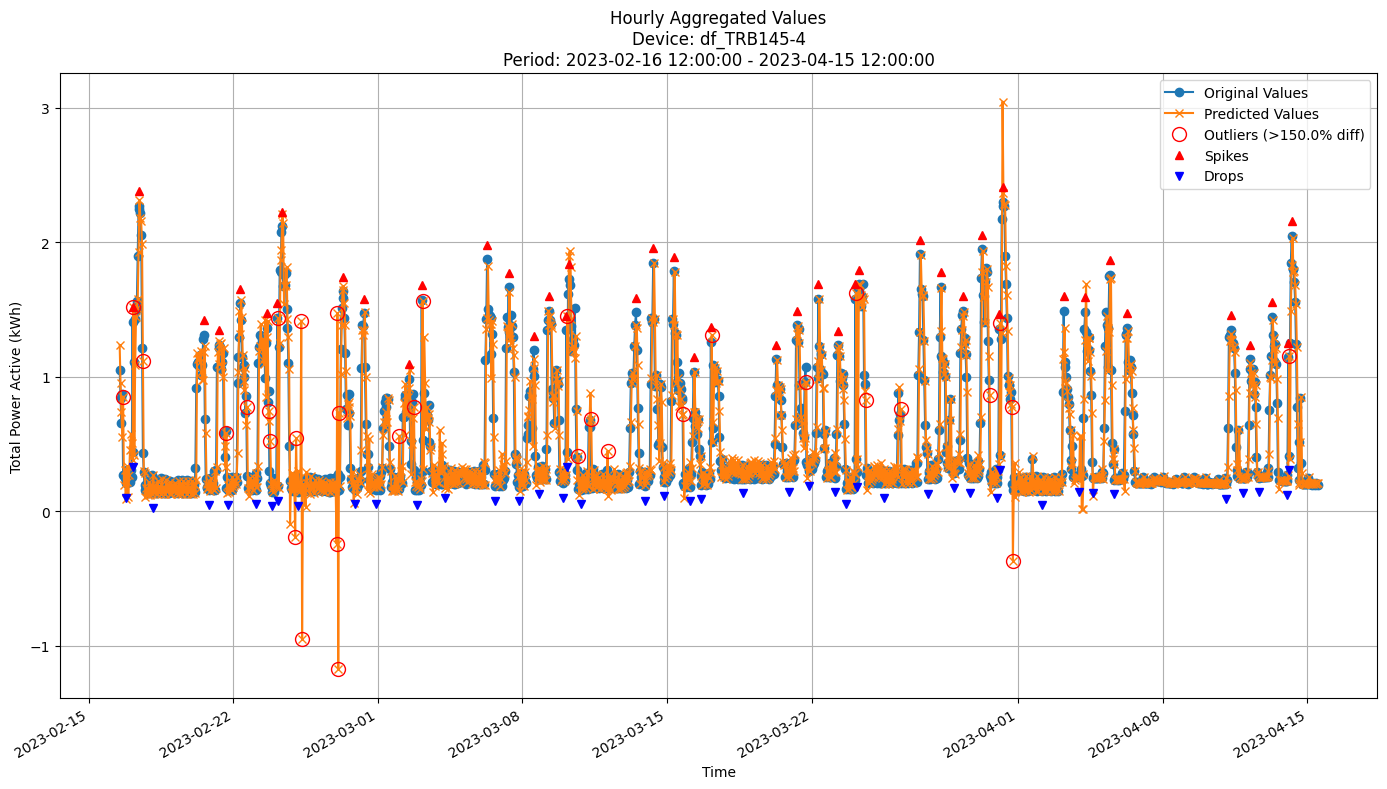


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2350
MAE: 0.1320
MAPE: 32.2103%

Directional Metrics:
Directional Accuracy: 39.0805%
First-Diff Correlation: 0.0127

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1190
  Recall: 0.1136
  F1 Score: 0.1163
Drops:
  Precision: 0.0476
  Recall: 0.0455
  F1 Score: 0.0465

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9048
  Recall: 0.8636
  F1 Score: 0.8837
Drops:
  Precision: 0.4762
  Recall: 0.4545
  F1 Score: 0.4651


In [57]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [62]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    xfodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-15 12:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2066
	MAE: 0.0944
	MAPE: 16.0510%

Directional Metrics:
	Directional Accuracy: 49.0775%
	First-Diff Correlation: 0.1927

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-04-15 12:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-15 14:00:00 to 2023-04-29 14:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-04-29 14:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-29 15:00:00 to 2023-05-13 15:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-05-13 15:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-13 16:00:00 to 2023-05-27 16:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-05-27 16:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-27 17:00:00 to 2023-05-30 18:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basi

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-15 12:00:00
Model's memory usage: 0.151848 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1841
	MAE: 0.0906
	MAPE: 17.8188%

Directional Metrics:
	Directional Accuracy: 51.4760%
	First-Diff Correlation: 0.2493

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2308
		Recall: 0.2308
		F1: 0.2308
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9744
		Recall: 0.9744
		F1: 0.9744
	Drops:
		Precision: 0.3684
		Recall: 0.3684
		F1: 0.3684
--------------------------------------------------
Daily Metrics:
----

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

[ERROR] Failed to initialize model 'ARFRegressorFODT' with parameters {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}.


TypeError: ARFRegressorFODT.__init__() got an unexpected keyword argument 'depth'

In [59]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [60]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [61]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "xFastODT": model_test_results[xfodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

KeyError: 'xFastODT'

In [54]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [ ]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.208 ± 0.000</td>
      <td>0.096 ± 0.000</td>
      <td>16.450 ± 0.000</td>
      <td>48.847 ± 0.000</td>
      <td>18.428 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.190 ± 0.000</td>
      <td>0.099 ± 0.000</td>
      <td>22.004 ± 0.000</td>
      <td>55.766 ± 0.000</td>
      <td>29.958 ± 0.000</td>
      <td>38.202 ± 0.000</td>
      <td>80.899 ± 0.000</td>
      <td>4.545 ± 0.000</td>
      <td>29.545 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.173 ± 0.000</td>
      <td>0.089 ± 0.000</td>
      <td>17.972 ± 0.000</td>
      <td>48.764 ± 0.000</td>
      <td>29.129 ± 0.000</td>
      <td>26.190 ± 0.000</td>
      <td>90.476 ± 0.000</td>
      <td>4.878 ± 0.000</td>
      <td>29.268 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.167 ± 0.000</td>
      <td>0.082 ± 0.000</td>
      <td>15.932 ± 0.000</td>
      <td>51.318 ± 0.000</td>
      <td>28.014 ± 0.000</td>
      <td>27.273 ± 0.000</td>
      <td>97.727 ± 0.000</td>
      <td>4.651 ± 0.000</td>
      <td>30.233 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.198 ± 0.000</td>
      <td>0.106 ± 0.000</td>
      <td>21.456 ± 0.000</td>
      <td>51.647 ± 0.000</td>
      <td>21.496 ± 0.000</td>
      <td>18.824 ± 0.000</td>
      <td>80.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>36.145 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.186 ± 0.000</td>
      <td>0.088 ± 0.000</td>
      <td>16.294 ± 0.000</td>
      <td>50.494 ± 0.000</td>
      <td>21.899 ± 0.000</td>
      <td>11.364 ± 0.000</td>
      <td>95.455 ± 0.000</td>
      <td>6.977 ± 0.000</td>
      <td>37.209 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.212 ± 0.000</td>
      <td>0.110 ± 0.000</td>
      <td>22.189 ± 0.000</td>
      <td>49.835 ± 0.000</td>
      <td>18.696 ± 0.000</td>
      <td>22.917 ± 0.000</td>
      <td>85.417 ± 0.000</td>
      <td>4.255 ± 0.000</td>
      <td>36.170 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.205 ± 0.000</td>
      <td>0.102 ± 0.000</td>
      <td>21.087 ± 0.000</td>
      <td>56.755 ± 0.000</td>
      <td>26.959 ± 0.000</td>
      <td>27.957 ± 0.000</td>
      <td>79.570 ± 0.000</td>
      <td>10.753 ± 0.000</td>
      <td>30.108 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.188 ± 0.000</td>
      <td>0.088 ± 0.000</td>
      <td>16.070 ± 0.000</td>
      <td>48.847 ± 0.000</td>
      <td>23.186 ± 0.000</td>
      <td>10.989 ± 0.000</td>
      <td>98.901 ± 0.000</td>
      <td>6.742 ± 0.000</td>
      <td>47.191 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [ ]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "xFastODT": xfodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.227 ± 0.042</td>
      <td>0.128 ± 0.031</td>
      <td>23.862 ± 7.597</td>
      <td>39.183 ± 4.839</td>
      <td>18.652 ± 19.926</td>
      <td>0.000 ± 0.000</td>
      <td>85.714 ± 34.993</td>
      <td>0.000 ± 0.000</td>
      <td>85.253 ± 34.822</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.189 ± 0.041</td>
      <td>0.117 ± 0.029</td>
      <td>25.727 ± 5.448</td>
      <td>45.743 ± 8.879</td>
      <td>28.821 ± 19.767</td>
      <td>20.717 ± 16.118</td>
      <td>63.929 ± 30.776</td>
      <td>3.378 ± 4.113</td>
      <td>28.702 ± 25.055</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.201 ± 0.040</td>
      <td>0.119 ± 0.036</td>
      <td>24.945 ± 5.082</td>
      <td>43.505 ± 6.421</td>
      <td>27.555 ± 15.964</td>
      <td>11.530 ± 12.847</td>
      <td>57.061 ± 38.309</td>
      <td>0.733 ± 1.794</td>
      <td>21.455 ± 14.867</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.117 ± 0.010</td>
      <td>0.069 ± 0.007</td>
      <td>13.657 ± 1.793</td>
      <td>48.332 ± 6.259</td>
      <td>65.099 ± 5.727</td>
      <td>12.706 ± 15.608</td>
      <td>43.963 ± 39.491</td>
      <td>6.683 ± 7.236</td>
      <td>11.346 ± 11.115</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.211 ± 0.042</td>
      <td>0.129 ± 0.027</td>
      <td>27.697 ± 6.308</td>
      <td>42.207 ± 4.036</td>
      <td>21.614 ± 18.275</td>
      <td>16.159 ± 14.655</td>
      <td>70.606 ± 31.123</td>
      <td>0.000 ± 0.000</td>
      <td>26.992 ± 13.409</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.198 ± 0.044</td>
      <td>0.115 ± 0.030</td>
      <td>22.913 ± 6.622</td>
      <td>42.017 ± 6.802</td>
      <td>23.203 ± 21.768</td>
      <td>12.276 ± 11.083</td>
      <td>76.743 ± 32.211</td>
      <td>2.765 ± 6.773</td>
      <td>39.297 ± 20.148</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.225 ± 0.039</td>
      <td>0.132 ± 0.029</td>
      <td>26.782 ± 8.276</td>
      <td>43.252 ± 6.035</td>
      <td>20.534 ± 17.332</td>
      <td>9.012 ± 12.607</td>
      <td>65.916 ± 33.154</td>
      <td>1.704 ± 2.721</td>
      <td>28.086 ± 22.909</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.226 ± 0.039</td>
      <td>0.139 ± 0.026</td>
      <td>31.303 ± 7.977</td>
      <td>50.831 ± 5.322</td>
      <td>32.192 ± 12.723</td>
      <td>21.880 ± 15.440</td>
      <td>56.239 ± 25.923</td>
      <td>6.463 ± 9.844</td>
      <td>27.376 ± 16.032</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.207 ± 0.043</td>
      <td>0.118 ± 0.032</td>
      <td>22.986 ± 7.411</td>
      <td>40.461 ± 4.427</td>
      <td>21.677 ± 19.850</td>
      <td>4.167 ± 6.682</td>
      <td>78.313 ± 32.205</td>
      <td>5.700 ± 7.946</td>
      <td>49.131 ± 28.542</td>
    </tr>
  </tbody>
</table>
</div>

### By-period validation results

In [57]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [ ]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)

#### MAPE (lower is better)

In [ ]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)

#### RMSE (lower is better)

In [ ]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)